<a href="https://colab.research.google.com/github/Raditya-Z/MachineLearning_244107020144/blob/main/JS-05/JS_05_Tugas.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Tugas
1. Pilih salah satu dataset nyata dari sklearn.datasets (misalnya iris dataset atau digits dataset).

2. Lakukan clustering dengan HDBSCAN.

3. Laporkan hasil:

- Jumlah cluster yang terbentuk.

- Banyaknya noise.

- Visualisasi (gunakan PCA/TSNE untuk reduksi dimensi jika perlu).

4. Buat analisis singkat: apakah hasil clustering HDBSCAN sesuai dengan label asli dataset tersebut?

# 1. Memilih Dataset Nyata

> Dataset yang digunakan adalah Iris Dataset dari pustaka sklearn.datasets. Dataset ini terdiri dari 150 data bunga dengan empat fitur, yaitu panjang sepal, lebar sepal, panjang petal, dan lebar petal.

> Dataset Iris memiliki tiga spesies bunga, yaitu Iris setosa, Iris versicolor, dan Iris virginica. Dataset ini digunakan untuk menguji kemampuan algoritma HDBSCAN dalam mengelompokkan data berdasarkan kemiripan karakteristiknya.

# 2. Melakukan Clustering dengan HDBSCAN

1. Memilih dataset Iris dan import library

In [2]:
# Instalasi library HDBSCAN
!pip install -q hdbscan

# Import library
import hdbscan
import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import load_iris
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.metrics import adjusted_rand_score

# Memuat dataset Iris
iris = load_iris()
X = iris.data
y_asli = iris.target

print("Jumlah data:", X.shape[0])
print("Jumlah fitur:", X.shape[1])
print("Nama spesies:", iris.target_names)


Jumlah data: 150
Jumlah fitur: 4
Nama spesies: ['setosa' 'versicolor' 'virginica']


2. Melakukan clustering menggunakan HDBSCAN

In [3]:
# Menyamakan skala data
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Membuat model HDBSCAN
clusterer = hdbscan.HDBSCAN(
    min_cluster_size=5,
    min_samples=5
)

# Melakukan clustering
labels = clusterer.fit_predict(X_scaled)

# Menghitung jumlah cluster
jumlah_cluster = len(set(labels)) - (1 if -1 in labels else 0)

# Menghitung jumlah noise
jumlah_noise = np.sum(labels == -1)

# Membandingkan hasil dengan label asli
ari = adjusted_rand_score(y_asli, labels)

# Menampilkan hasil
print("Hasil Clustering HDBSCAN")
print("------------------------")
print("Jumlah cluster :", jumlah_cluster)
print("Jumlah noise   :", jumlah_noise)
print("Nilai ARI      :", round(ari, 3))

Hasil Clustering HDBSCAN
------------------------
Jumlah cluster : 2
Jumlah noise   : 2
Nilai ARI      : 0.539


3. Visualisasi dan analisis hasil clustering

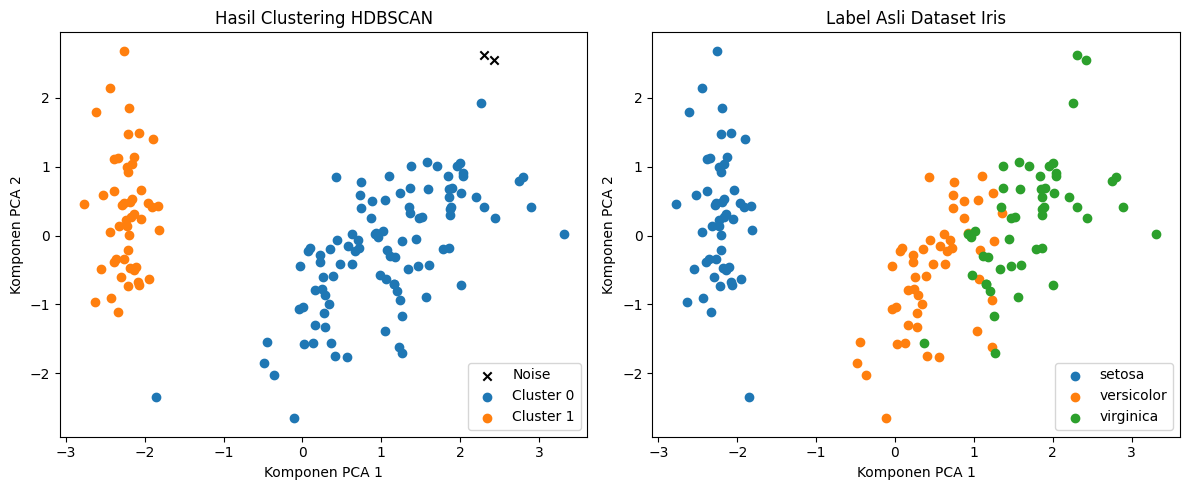

In [4]:
# Mengurangi dimensi data menggunakan PCA
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

# Membuat dua grafik perbandingan
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Grafik hasil clustering HDBSCAN
for cluster in sorted(set(labels)):
    data = X_pca[labels == cluster]

    if cluster == -1:
        axes[0].scatter(
            data[:, 0],
            data[:, 1],
            c="black",
            marker="x",
            label="Noise"
        )
    else:
        axes[0].scatter(
            data[:, 0],
            data[:, 1],
            label=f"Cluster {cluster}"
        )

axes[0].set_title("Hasil Clustering HDBSCAN")
axes[0].set_xlabel("Komponen PCA 1")
axes[0].set_ylabel("Komponen PCA 2")
axes[0].legend()

# Grafik label asli Iris
for spesies in np.unique(y_asli):
    data = X_pca[y_asli == spesies]

    axes[1].scatter(
        data[:, 0],
        data[:, 1],
        label=iris.target_names[spesies]
    )

axes[1].set_title("Label Asli Dataset Iris")
axes[1].set_xlabel("Komponen PCA 1")
axes[1].set_ylabel("Komponen PCA 2")
axes[1].legend()

plt.tight_layout()
plt.show()

3. Hasil Clustering dan Visualisasi

Berdasarkan hasil program yang telah dijalankan, algoritma HDBSCAN pada dataset Iris menghasilkan 2 cluster dan 2 data noise dari total 150 data bunga.

Visualisasi dilakukan menggunakan Principal Component Analysis (PCA) untuk mengurangi empat fitur asli menjadi dua komponen, sehingga pola pengelompokan lebih mudah diamati.
- Jumlah cluster: 2 cluster.
- Jumlah noise: 2 data, ditandai dengan simbol silang hitam pada grafik.
- Visualisasi HDBSCAN: grafik pertama menunjukkan hasil pengelompokan data menjadi dua cluster dengan warna berbeda.
- Label asli dataset: grafik kedua menunjukkan tiga spesies bunga, yaitu Iris setosa, Iris versicolor, dan Iris virginica.
- Evaluasi clustering: nilai Adjusted Rand Index (ARI) digunakan untuk mengukur kesesuaian hasil clustering dengan label asli dataset.

Perbandingan kedua grafik menunjukkan bahwa HDBSCAN menghasilkan dua kelompok, sedangkan dataset Iris memiliki tiga spesies asli. Nilai ARI dari output program dapat digunakan untuk mendukung penilaian kesesuaian tersebut.

4. Analisis Kesesuaian dengan Label Asli

> Hasil clustering HDBSCAN menunjukkan bahwa dataset Iris terbagi menjadi dua cluster, sedangkan label aslinya terdiri dari tiga spesies bunga. Berdasarkan visualisasi PCA, cluster pertama sebagian besar berisi bunga Iris setosa, sedangkan cluster lainnya mencakup sebagian besar bunga Iris versicolor dan Iris virginica.

> Hasil tersebut menunjukkan bahwa HDBSCAN mampu memisahkan sebagian karakteristik bunga berdasarkan kepadatan data, tetapi belum berhasil memisahkan ketiga spesies menjadi kelompok yang berbeda. Hal ini dapat terjadi karena karakteristik Iris versicolor dan Iris virginica memiliki kemiripan sehingga sebagian datanya sulit dipisahkan secara jelas.

> Selain itu, terdapat dua data yang dikategorikan sebagai noise karena tidak dimasukkan ke dalam cluster berdasarkan parameter yang digunakan. Perlu diperhatikan bahwa PCA hanya digunakan untuk visualisasi, sedangkan proses clustering dilakukan pada data hasil standardisasi dengan empat fitur.

Kesimpulan: HDBSCAN berhasil membentuk dua cluster dan mengidentifikasi dua data noise pada dataset Iris. Namun, hasil clustering belum sepenuhnya sesuai dengan label asli yang terdiri dari tiga spesies. Tingkat kesesuaiannya secara numerik perlu dilihat dari nilai ARI yang dihasilkan program.